# Run Huffman and Quad Tree compression algorithms

In [1]:
# Import libraries
from pathlib import Path

from IPython.display import display
from PIL import Image

from huffman.encoding import encode_image
from huffman.decoding import decode_image
from quad_tree.quad_tree_compression import compress_image_file, reconstruct_image_from_file
from benchmarks import AlgorithmConfig, benchmark_images, format_benchmark_results


## Original Image

In [ ]:
display(Image.open("data/dog.JPEG"))

## Huffman

In [ ]:
input_path = "data/dog.JPEG"
output_path = "data/dog_compressed.bin"
encode_image(input_path, output_path)
decode_image(output_path, "data/dog_decompressed.png")

display(Image.open("data/dog_decompressed.png"))

## Quad Tree

In [ ]:
# Compress the image and encode is a binary file (any file extension can be chosen)
compress_image_file("data/dog.JPEG", "data/dog_qt.qid", iterations=20_000)

# Reconstruct the image from the binary file. (Returns a PIL.Image object)
image = reconstruct_image_from_file("data/dog_qt.qid")
display(image)

image.save("data/dog_reconstructed.jpg")

## Benchmarking

Calculate benchmark statistics

In [2]:
def compress_huffman(input_path, output_path, iteration_count=None):
    encode_image(input_path, output_path)

def compress_quadtree(input_path, output_path, iteration_count):
    compress_image_file(input_path, output_path, iterations=iteration_count)

def decompress_quadtree(input_path, output_path):
    reconstruct_image_from_file(input_path).save(output_path)

algorithms = {
    "Huffman": AlgorithmConfig(
        compressor=compress_huffman,
        decompressor=decode_image,
    ),
    "Quad Tree": AlgorithmConfig(
        compressor=compress_quadtree,
        decompressor=decompress_quadtree,
        lossy=True,
        iteration_counts=(100, 1_000, 20_000, 80_000),
    ),
}

image_paths = ["data/dog.JPEG"]

# Get timing and size results
results = benchmark_images(
    image_paths,
    algorithms,
    reconstruction_directory="data/benchmark_reconstructions",
)
print(format_benchmark_results(results))

+----------+-------------------------------+---------------+-----------------+-----------+-------+--------------+----------------+
| Image    | Algorithm                     | Original (KB) | Compressed (KB) | Reduction | MAE   | Compress (s) | Decompress (s) |
+----------+-------------------------------+---------------+-----------------+-----------+-------+--------------+----------------+
| dog.JPEG | Huffman                       | 576.75        | 9,240.13        | -1502.11% | 0.00  | 1.813        | 3.941          |
| dog.JPEG | Quad Tree (100 iterations)    | 576.75        | 0.96            | 99.83%    | 11.38 | 0.685        | 0.040          |
| dog.JPEG | Quad Tree (1,000 iterations)  | 576.75        | 7.75            | 98.66%    | 6.12  | 0.950        | 0.049          |
| dog.JPEG | Quad Tree (20,000 iterations) | 576.75        | 116.22          | 79.85%    | 2.35  | 2.850        | 0.242          |
| dog.JPEG | Quad Tree (80,000 iterations) | 576.75        | 378.50          | 34.3

Before/After images

Original: dog.JPEG


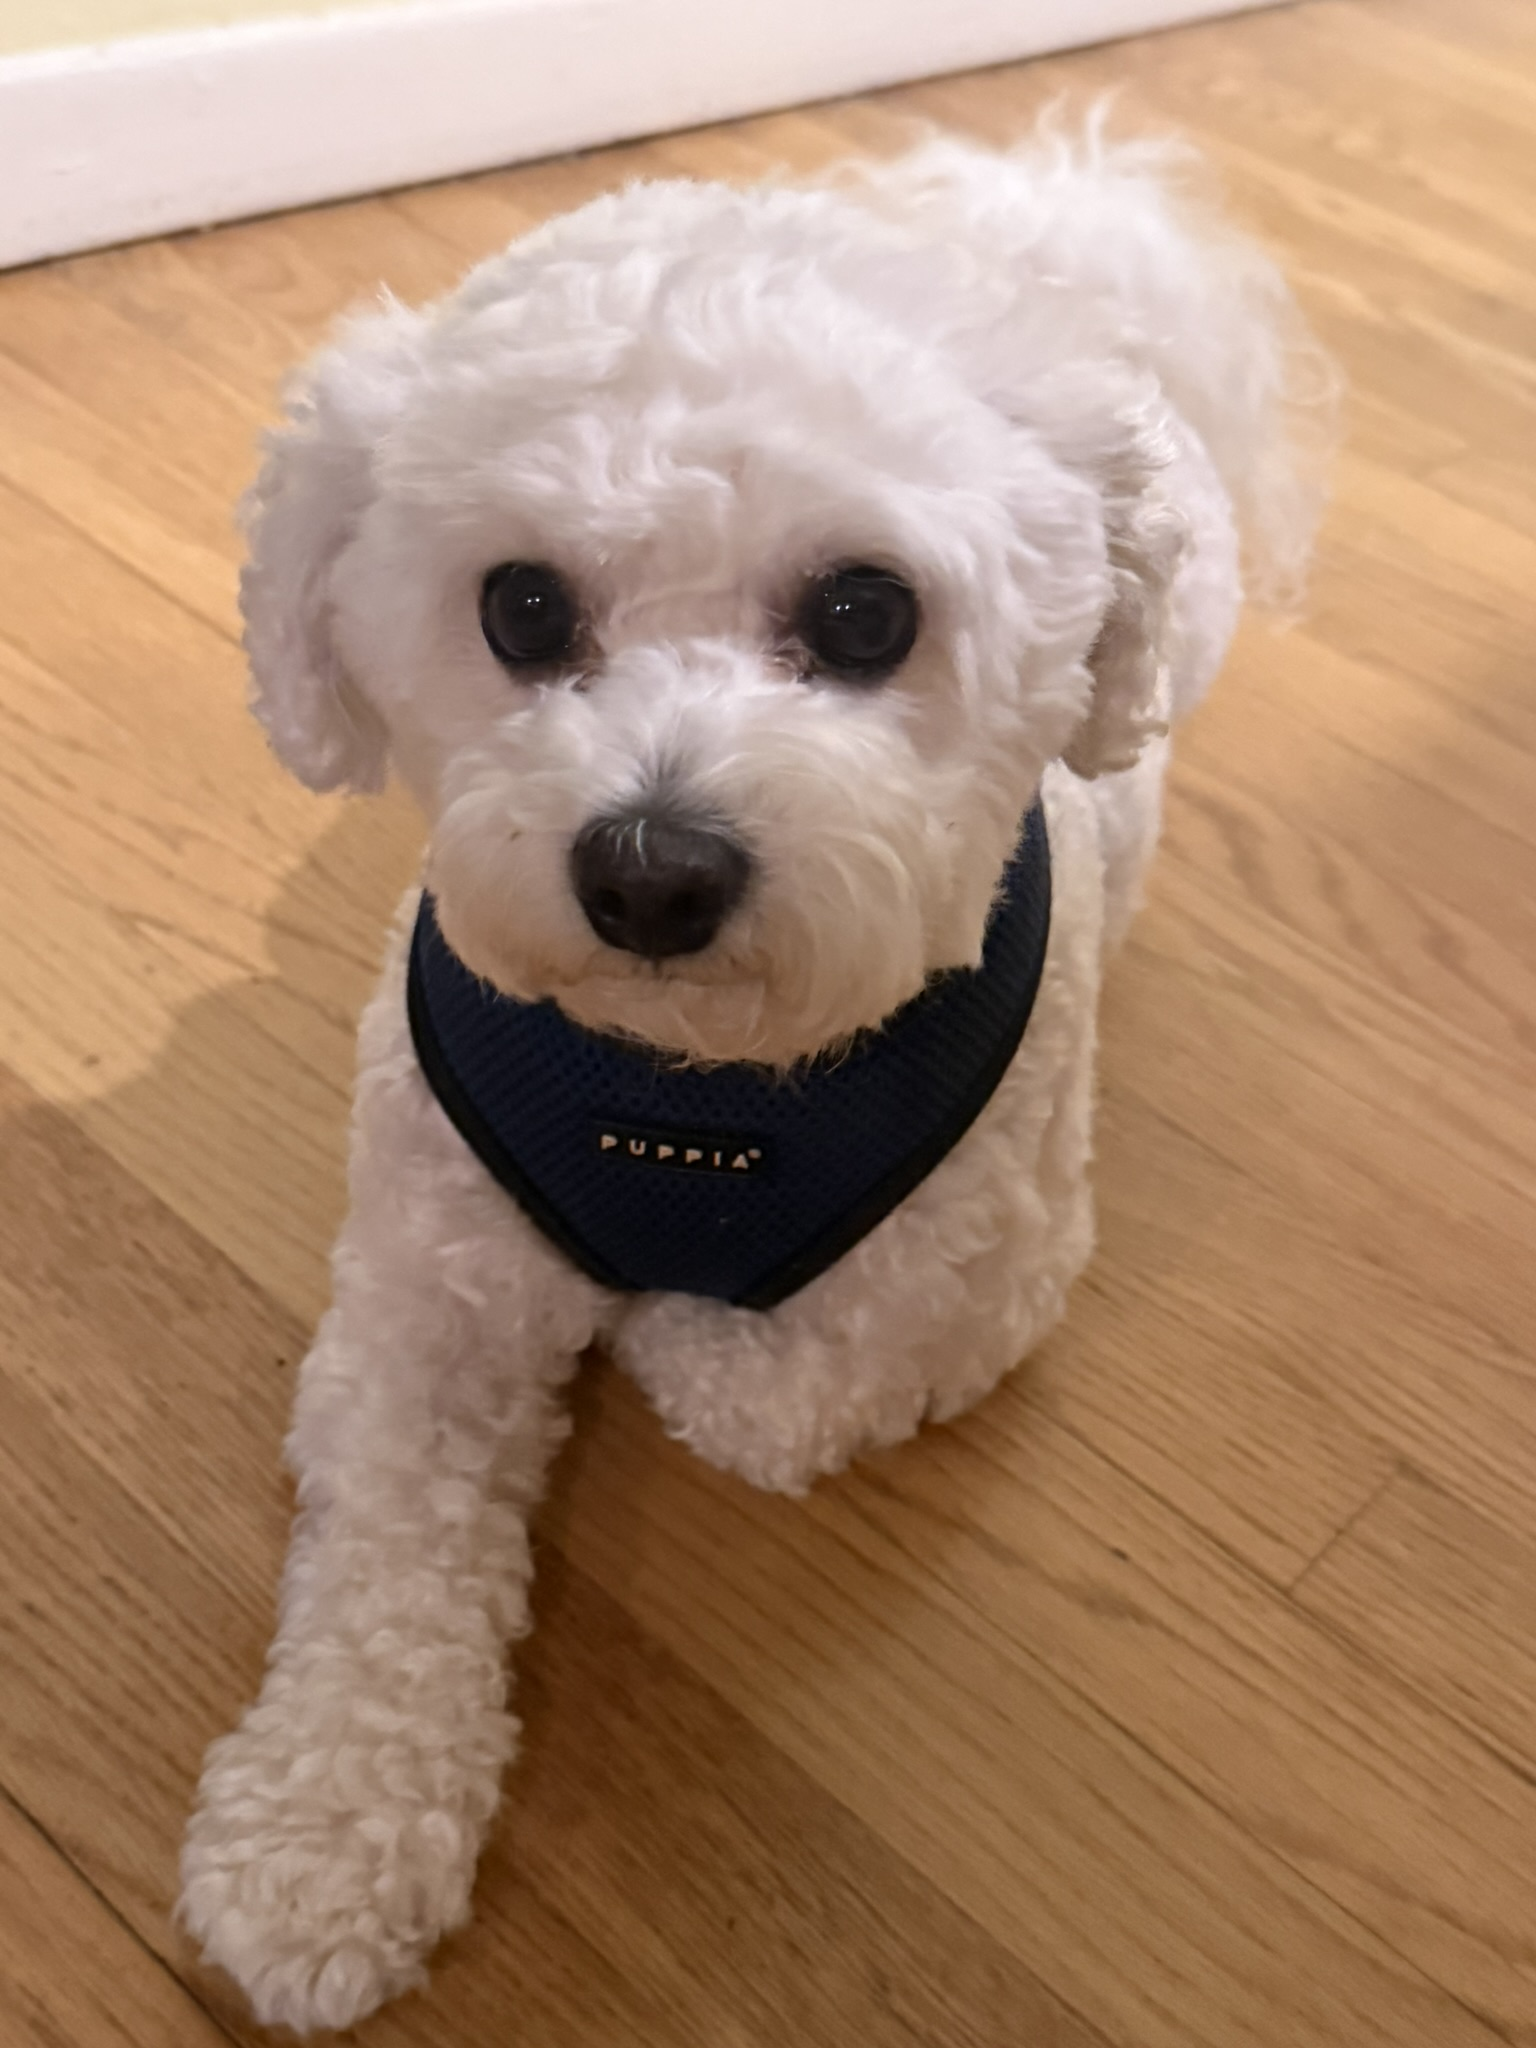

Huffman


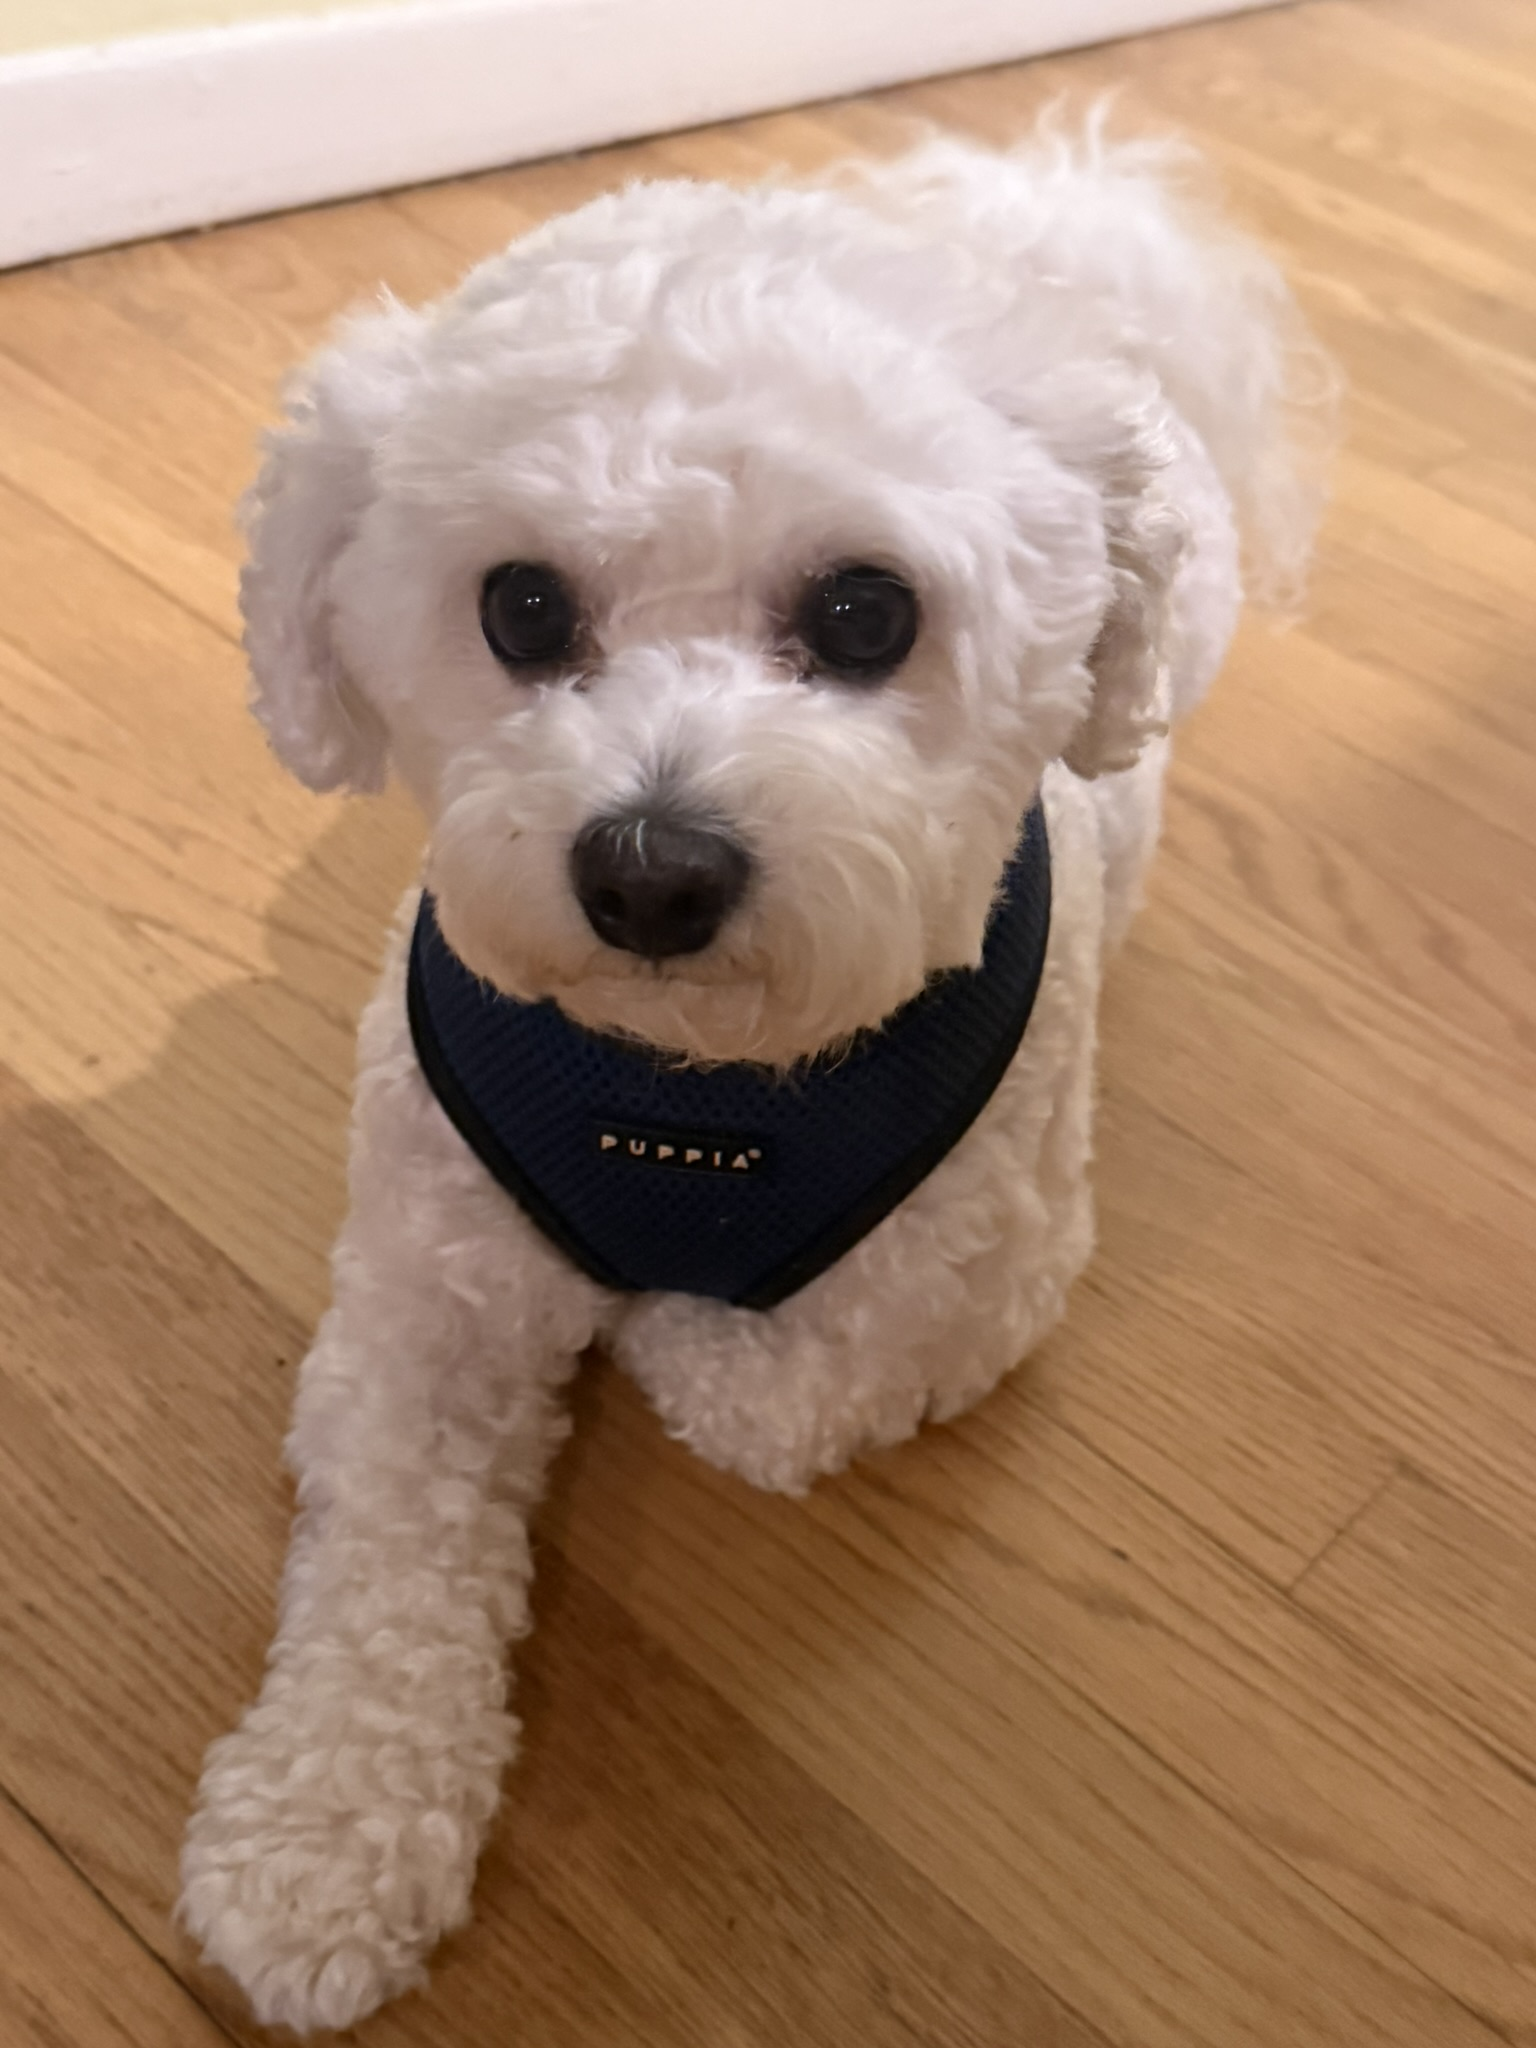

Quad Tree (100 iterations)


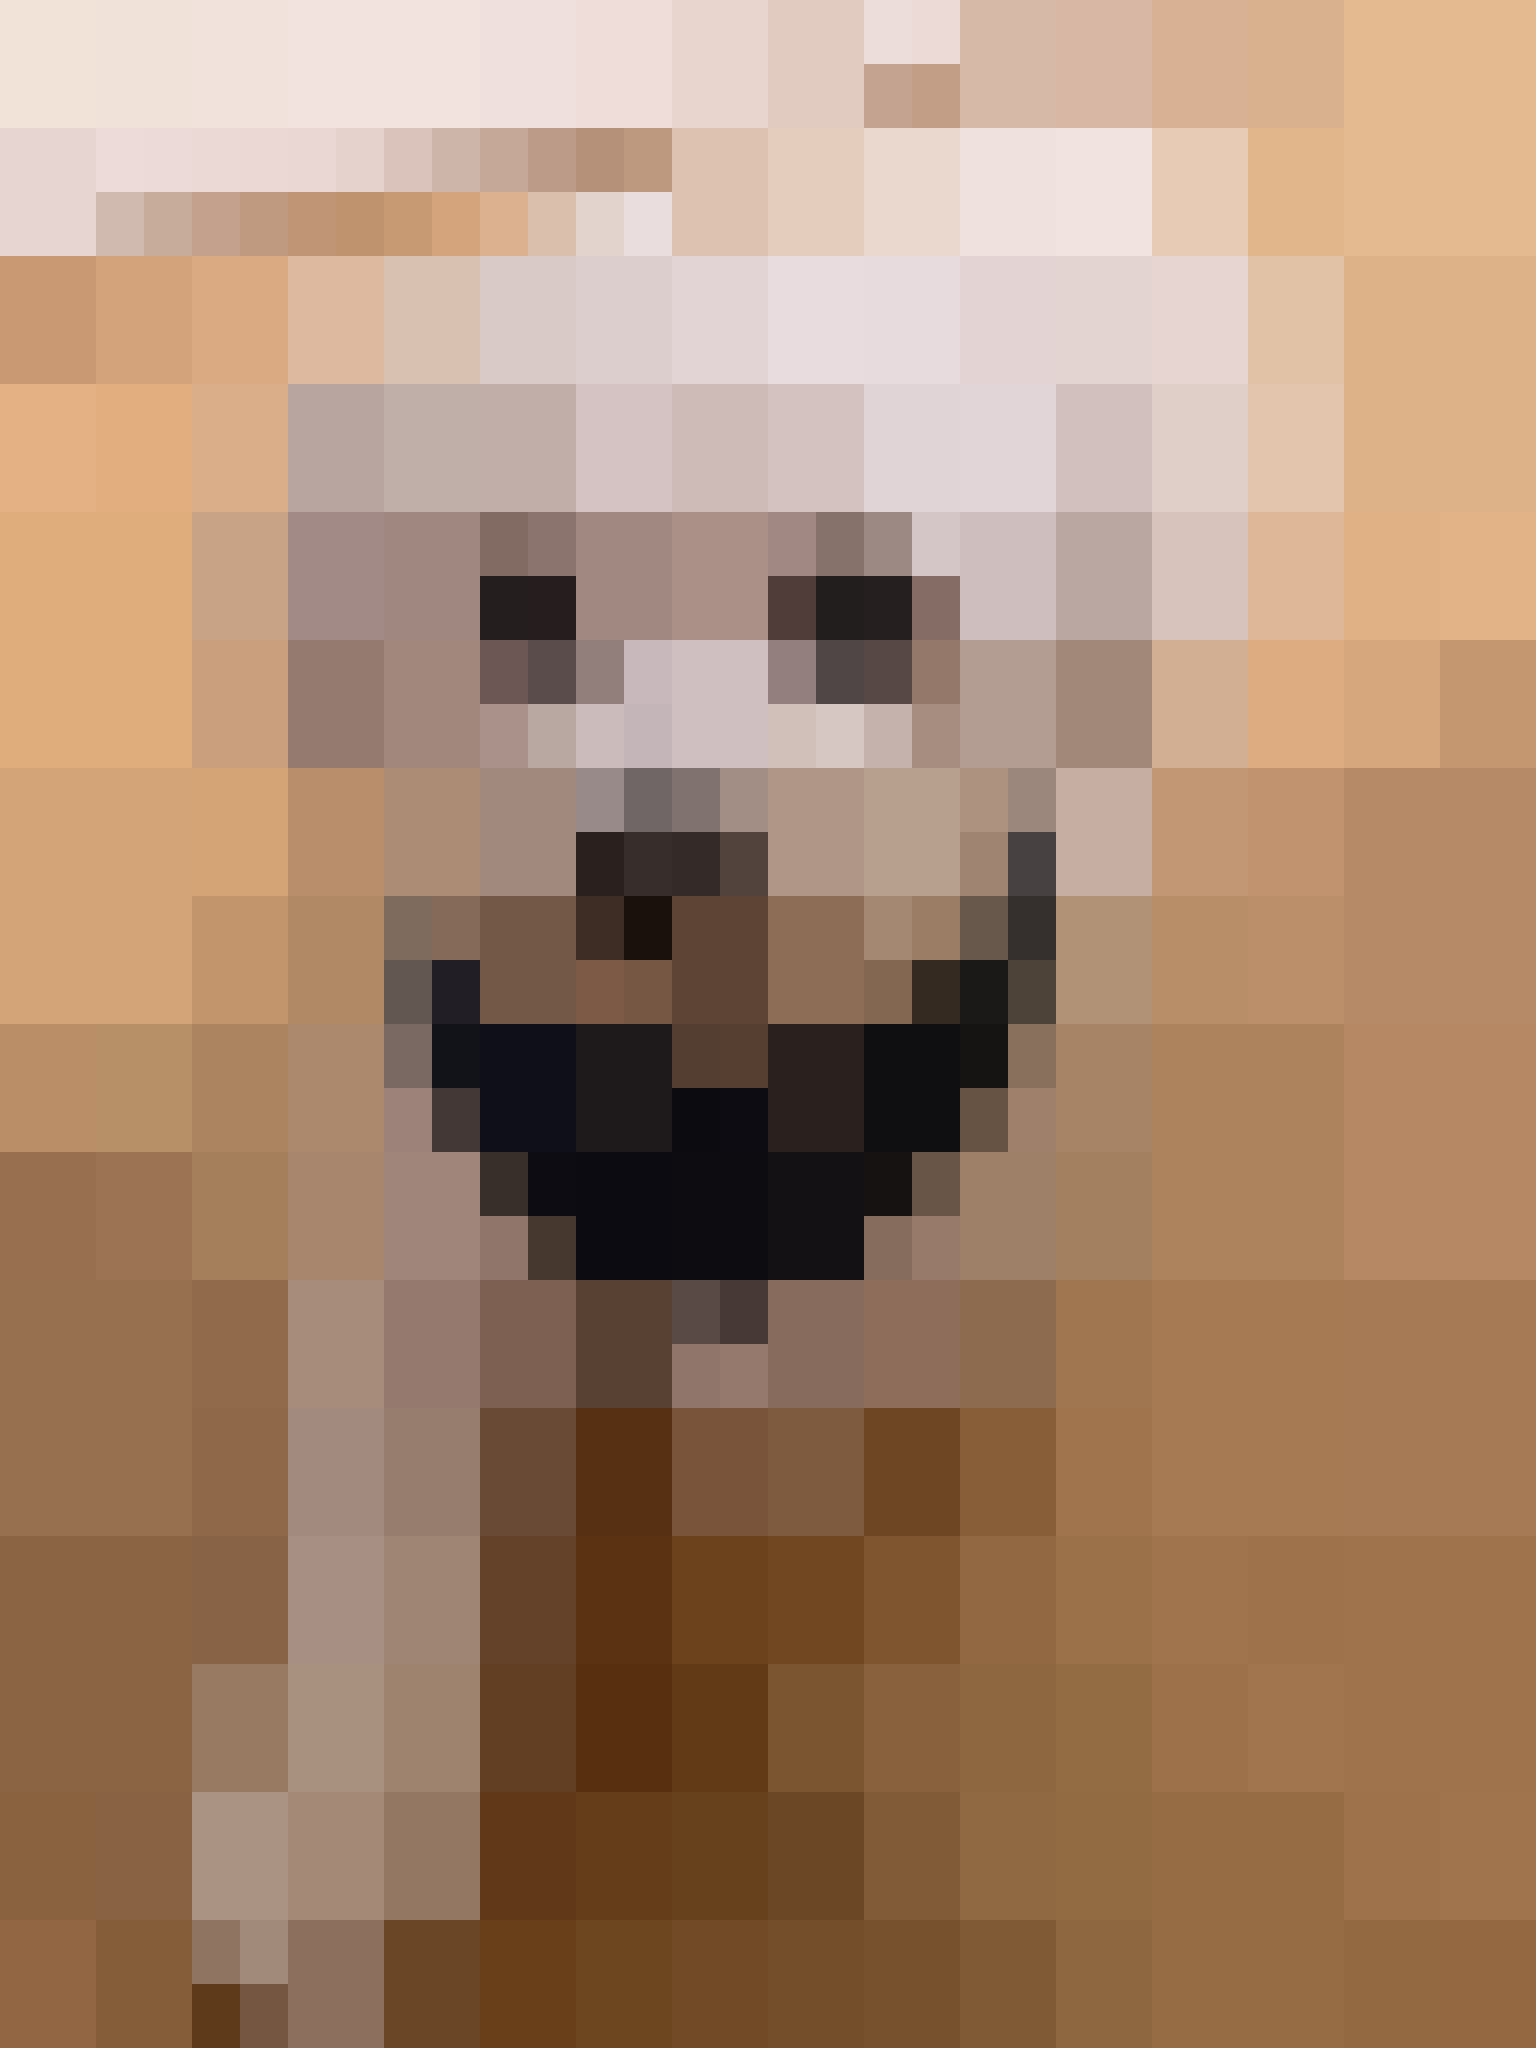

Quad Tree (1,000 iterations)


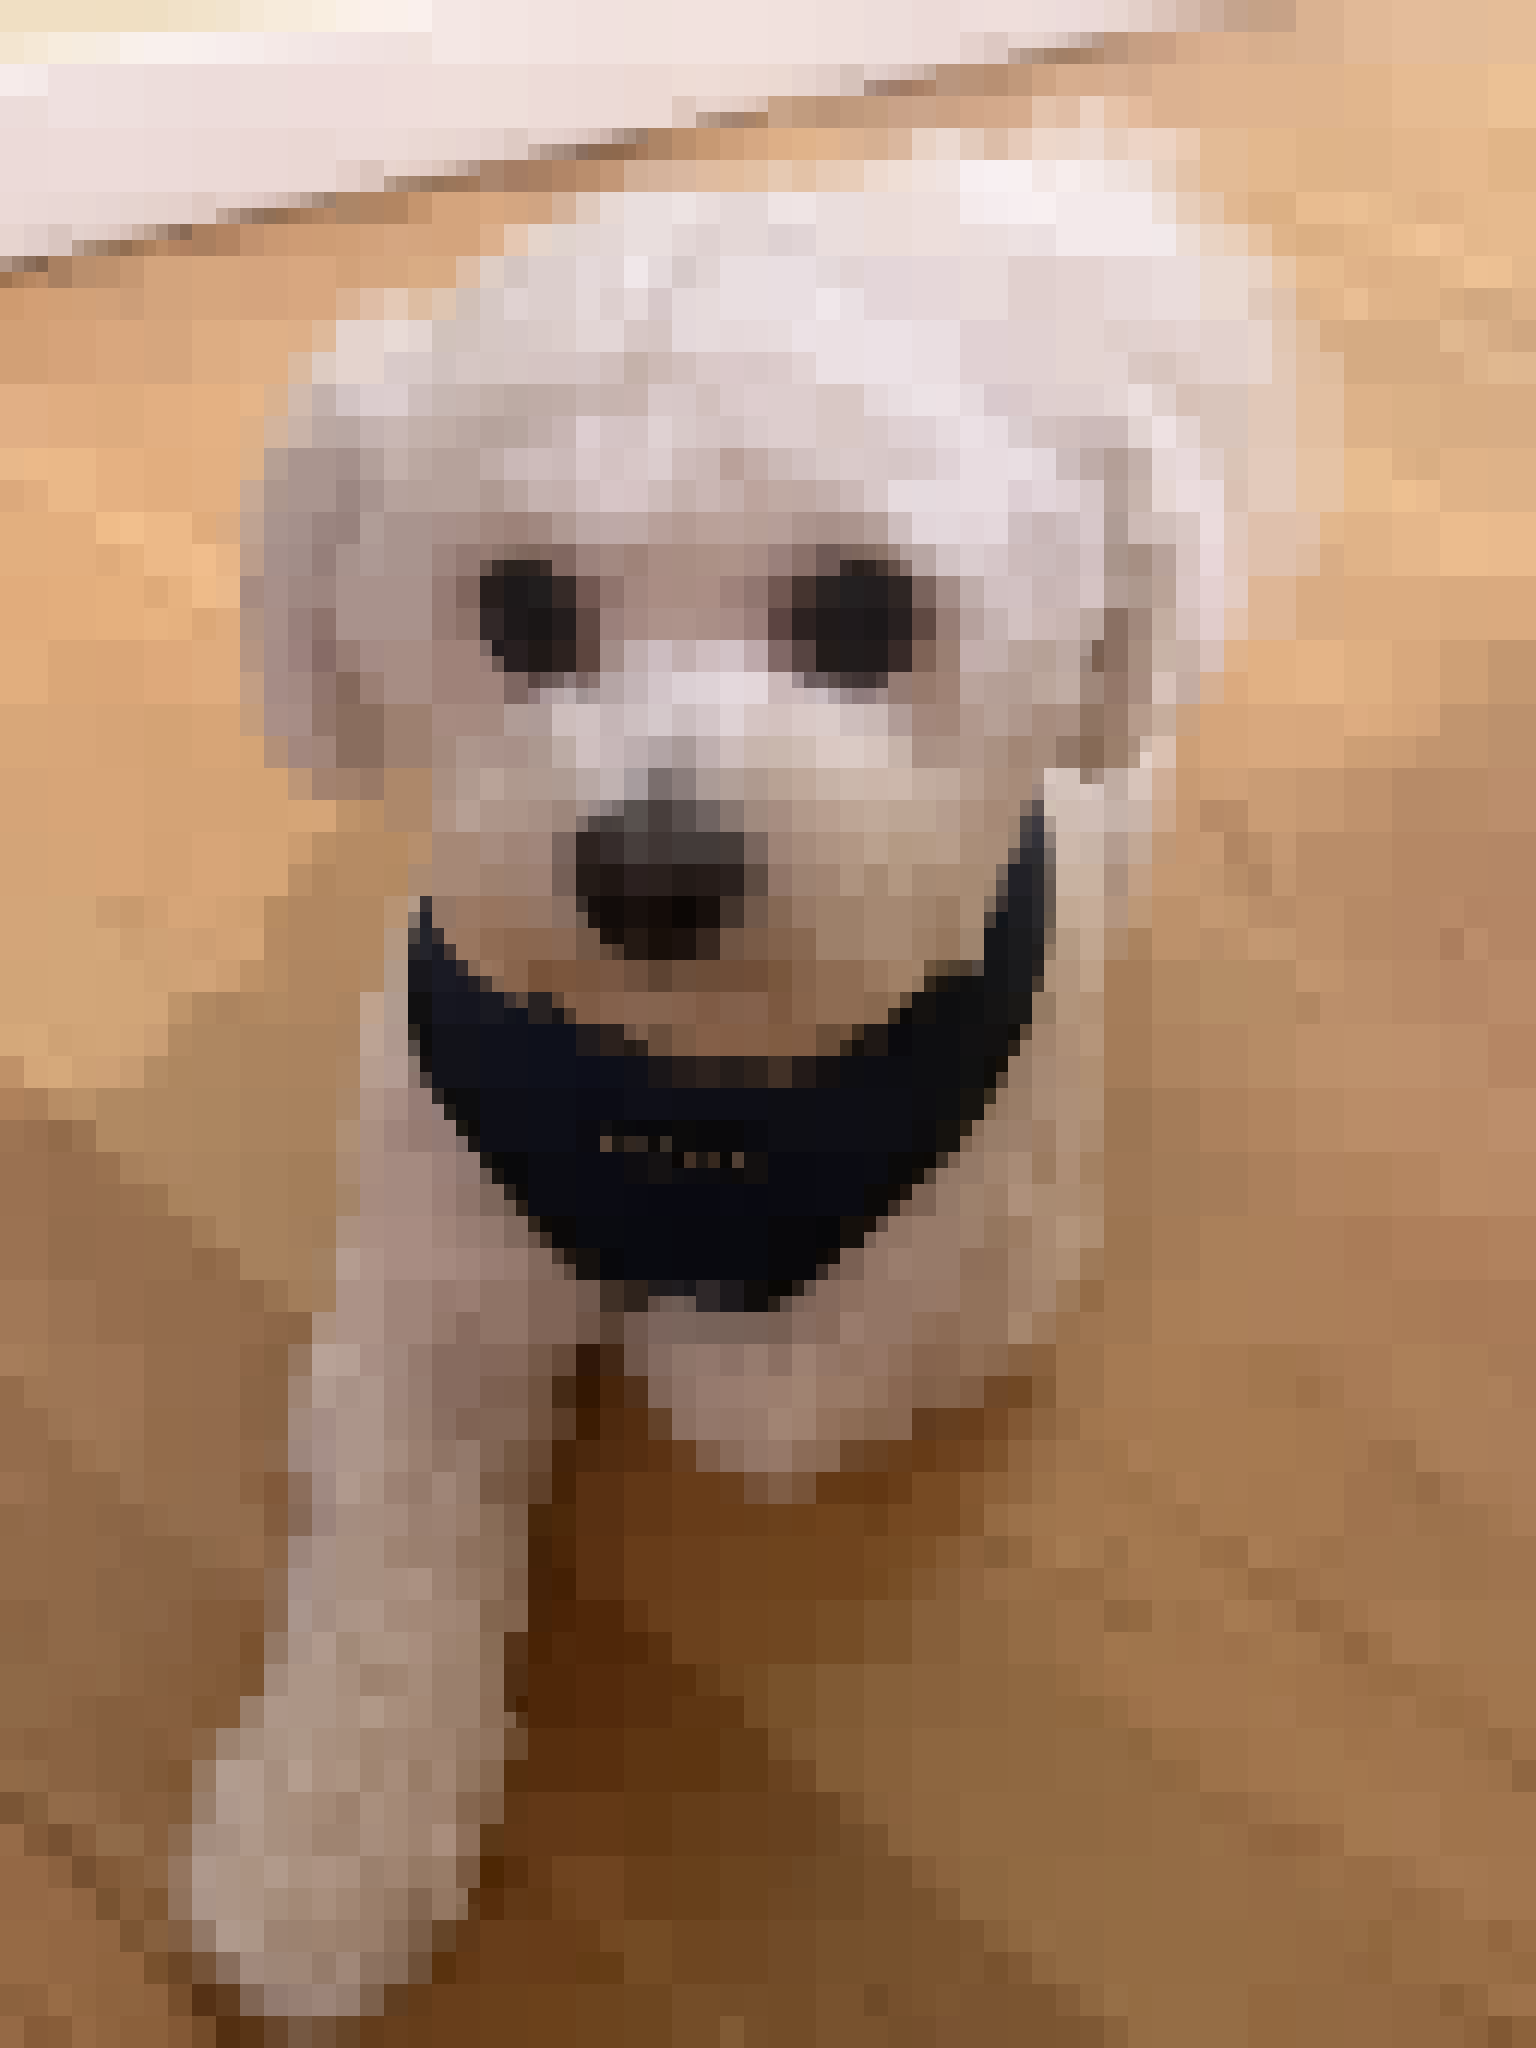

Quad Tree (20,000 iterations)


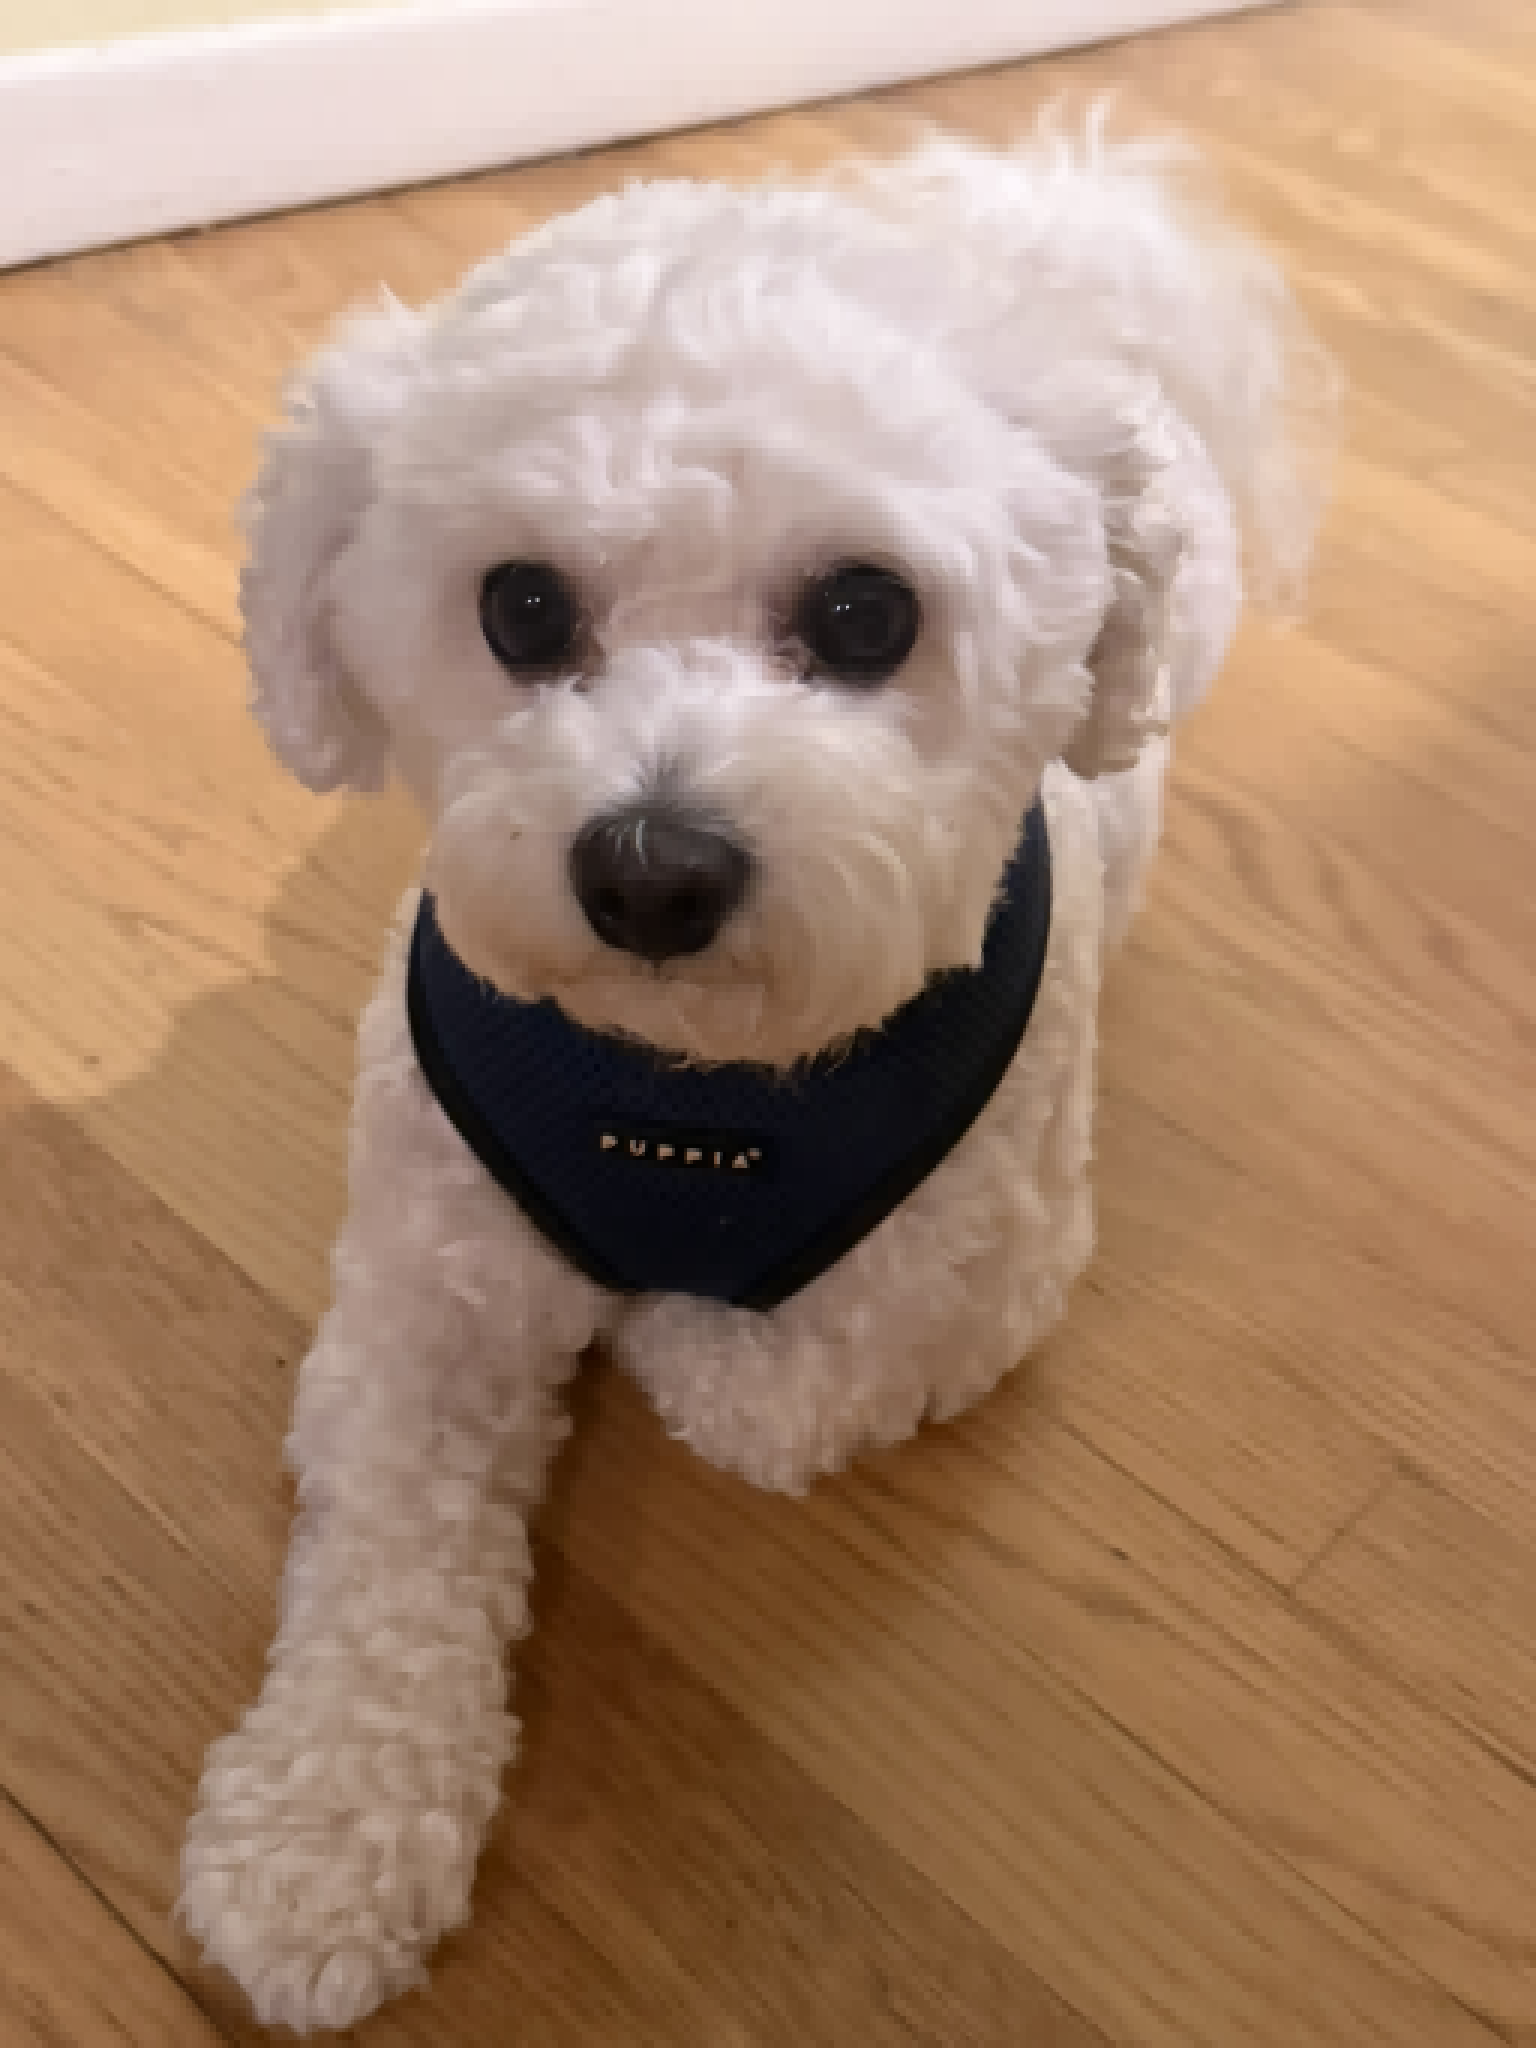

Quad Tree (80,000 iterations)


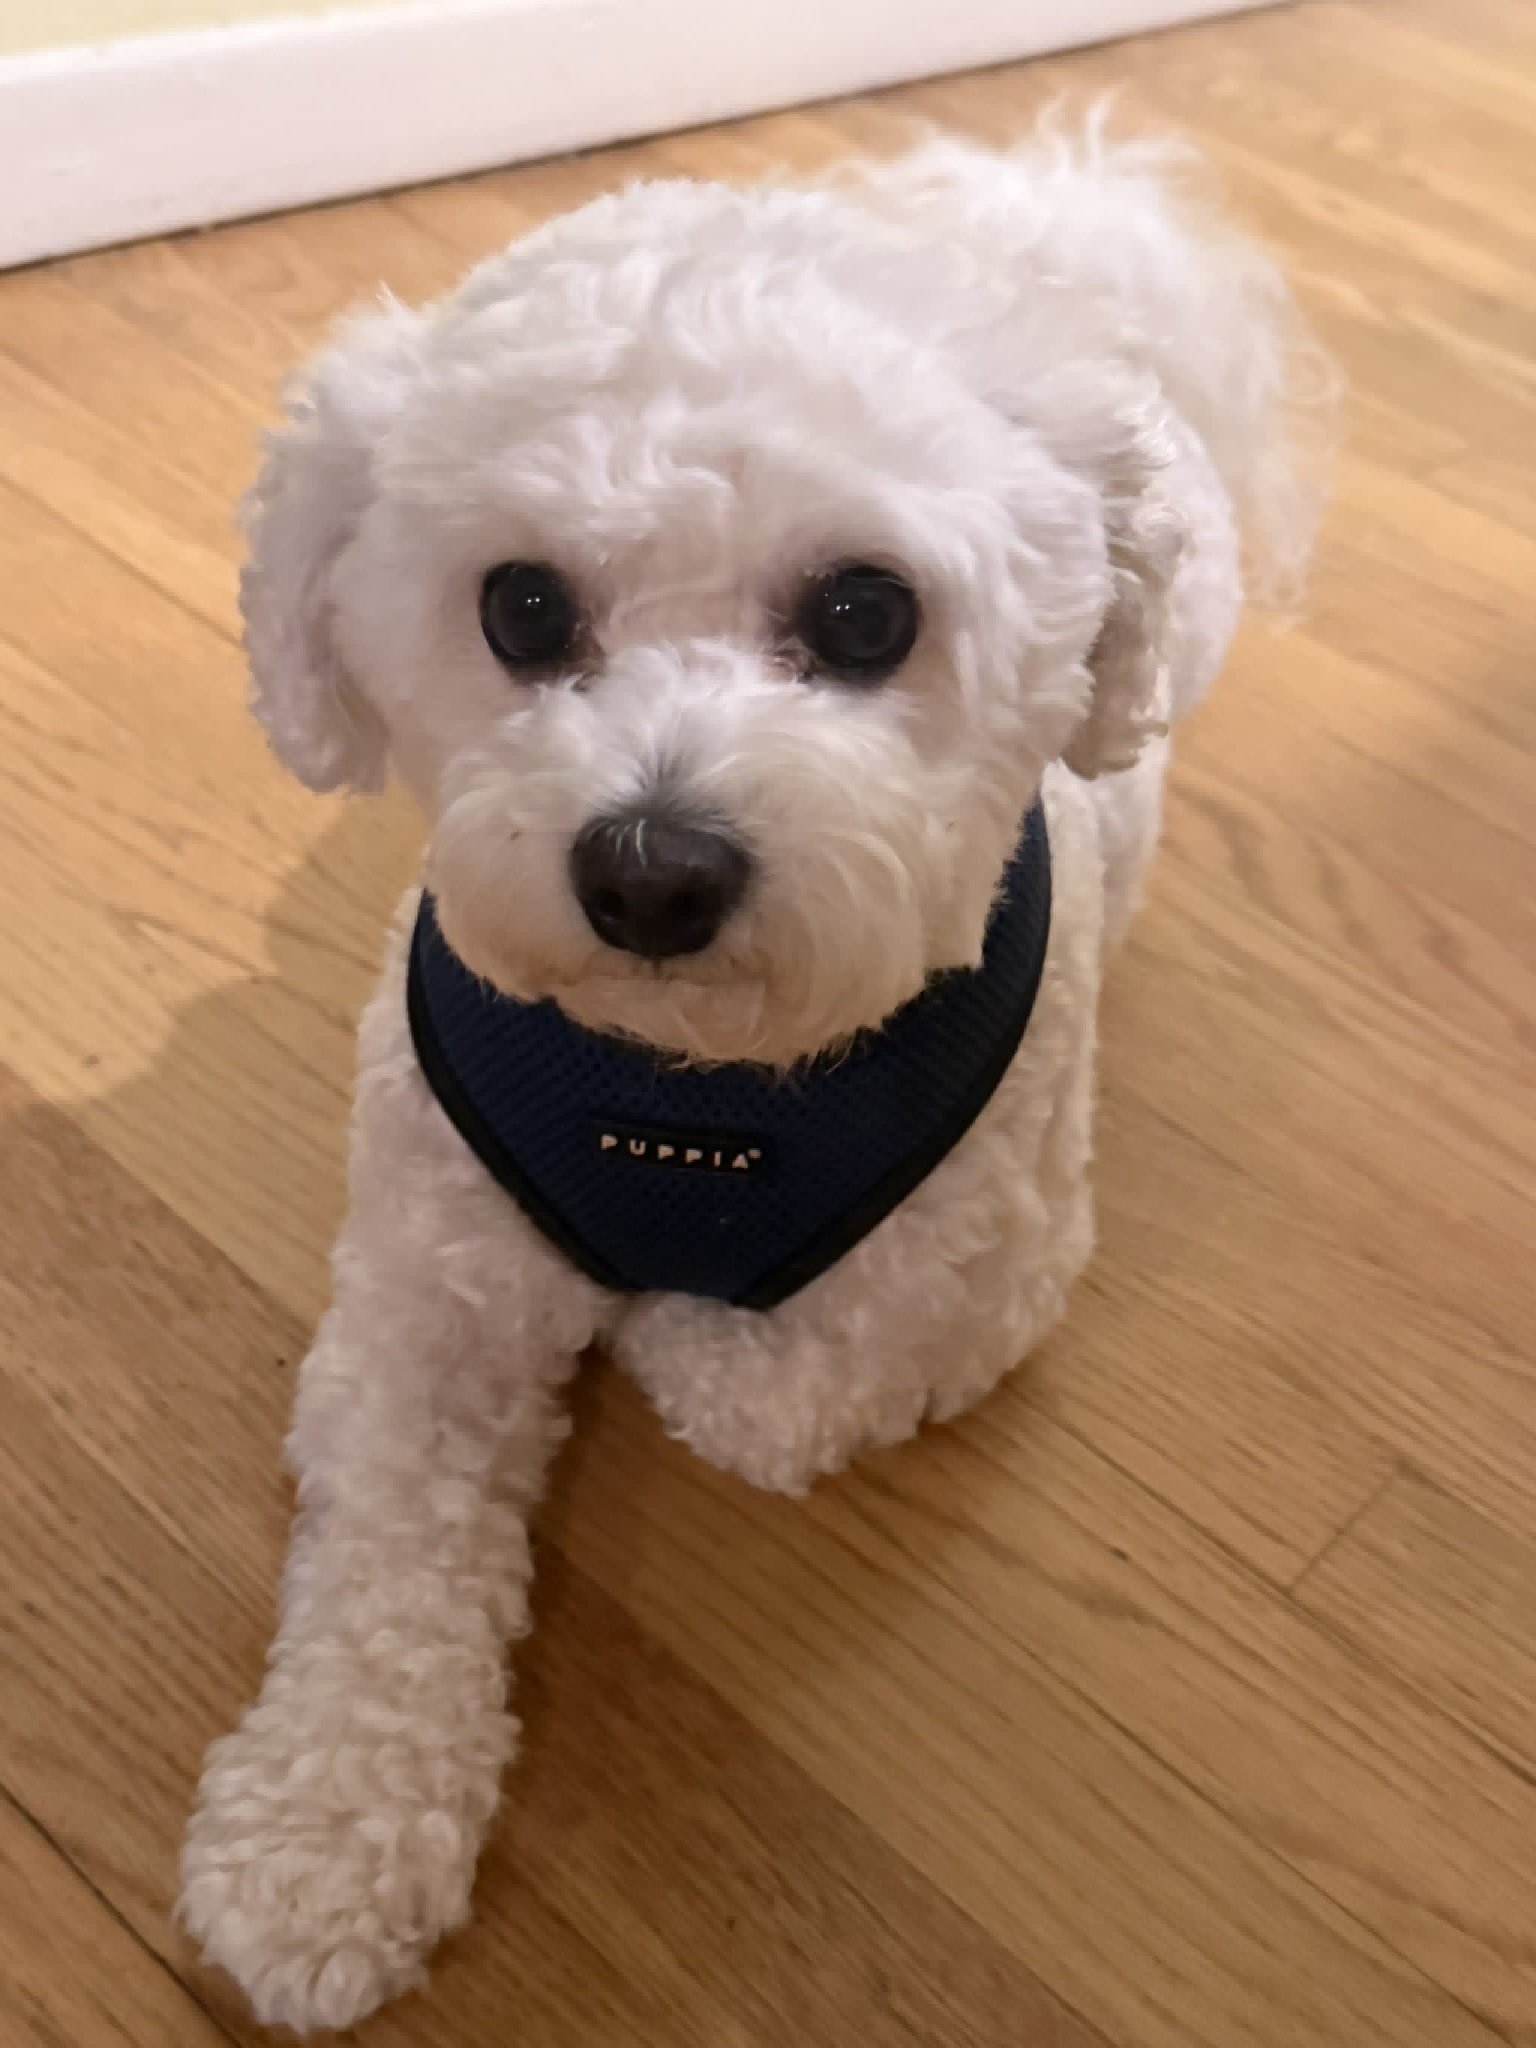

In [ ]:
# Display the original and reconstructed images

for image_path in map(Path, image_paths):
    print(f"Original: {image_path.name}")
    with Image.open(image_path) as original:
        display(original.copy())

    image_results = [result for result in results if result.image_path == image_path]
    for result in image_results:
        if result.reconstruction_path is None:
            raise RuntimeError("Benchmark result has no saved reconstruction")
        iteration_label = (
            "" if result.iteration_count is None
            else f" ({result.iteration_count:,} iterations)"
        )
        print(f"{result.algorithm}{iteration_label}")
        with Image.open(result.reconstruction_path) as reconstruction:
            display(reconstruction.copy())